# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [2]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """
    import json

    with open(file_path, "r", encoding="utf-8") as file:
       data = json.load(file)

    return data["texts"]

texts = extract_texts_from_file('resources/data.json')
print(texts)

['Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.', "Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.", 'In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.', 'Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.', 'Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats. With webbed feet and waterpr

## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [3]:
def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    import re 
    from nltk.stem import PorterStemmer
    from textblob import TextBlob

    stemmer = PorterStemmer()

    abbreviations = { 
        "dr": "doctor", 
        "mr": "mister", 
        "mrs": "misses", 
        "etc": "etcetera" 
    }
    
    processed_texts = []
    
    for text in texts: 
        text = text.lower() 
        text = re.sub(r"[^a-z\s]", "", text) 
        text = re.sub(r"\s+", " ", text).strip()
        
        words = text.split()

        words = [abbreviations.get(word, word) for word in words]

        words = [str(TextBlob(word).correct()) for word in words]

        words = [stemmer.stem(word) for word in words]

        text = " ".join(words)
        processed_texts.append(text)
    
    return processed_texts

texts_processed = process_texts(texts)
print(texts_processed)

['oppenheim direct by christoph woman delv into the life of j robert oppenheim the theoret physician who led the develop of the atom bomb the film explor hi moral and emot struggl', 'oppenheim captur the life of the father of the atom bomb and hi intern conflict after the success of the manhattan project the film complex narr reflect on the cost of scientif achiev', 'in oppenheim million murphi deliv a riot perform as the conflict physician who grappl with the consequ of hi groundbreak work on the atom bomb under the weight of global polit and ethic', 'oppenheim is a cinemat explor of ambit guilt and respons through stun visual and a thoughtprovok stori woman bring the life of the brilliant but haunt physician to the big screen', 'duck are versatil waterfowl known for their adapt in freshwat and coastal habitat with web feet and waterproof feather they are excel swimmer migrat long distanc to find food and warmer climat', 'the lamp is a spider but it talk yesterday i flew but nobodi no

## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [5]:
def calcuate_tfidf(texts_processed):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(texts_processed)

    cosine_matrix = cosine_similarity(tfidf_matrix)
    
    return cosine_matrix.tolist()

cosine_matrix = calcuate_tfidf(texts_processed)
print(cosine_matrix)

[[1.0, 0.43779619134056263, 0.3421245496976578, 0.31566507603688854, 0.01578117437924989, 0.06485351150394178, 0.09279348911802168, 0.044072423170471504, 0.06899712291455137, 0.08435613693216214], [0.43779619134056263, 1.0, 0.38652713896590796, 0.27099549246578064, 0.014125572174745752, 0.07948307418160167, 0.13781457416630855, 0.05128269475968682, 0.04724402218302026, 0.12850930922936887], [0.3421245496976578, 0.38652713896590796, 1.0000000000000002, 0.1894798193935564, 0.054740261096187785, 0.052937536080932324, 0.10994814512790815, 0.04913130642708783, 0.08603261407237461, 0.08941859474999996], [0.31566507603688854, 0.27099549246578064, 0.1894798193935564, 1.0, 0.05593608202864463, 0.13234228410787122, 0.09582703488776745, 0.07514959295208354, 0.05733726799376108, 0.08118740504316785], [0.01578117437924989, 0.014125572174745752, 0.054740261096187785, 0.05593608202864463, 1.0000000000000002, 0.06329181873363252, 0.13824974466123122, 0.04215264444184061, 0.12159403026463453, 0.0263463

## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

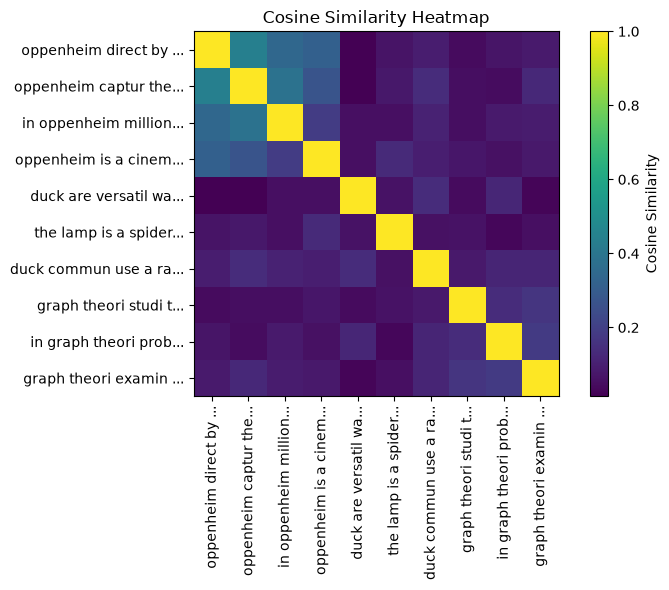

In [6]:
def visualize_data(cosine_matrix, texts_processed):
    """
    Visualize the cosine similarity matrix from the previous task. 

    Args:
        cosine_matrix (list): matrix of cosine similarity scores (values from 0.0 to 1.0 expected).
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        None: None.
    """
    import matplotlib.pyplot as plt

    plt.figure(figsize=(8, 6))
    plt.imshow(cosine_matrix)
    plt.colorbar(label="Cosine Similarity")
    
    labels = [text[:20] + "..." for text in texts_processed]
    plt.xticks(range(len(labels)), labels, rotation=90)
    plt.yticks(range(len(labels)), labels)
    
    plt.title("Cosine Similarity Heatmap")
    plt.tight_layout()
    plt.show()

visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

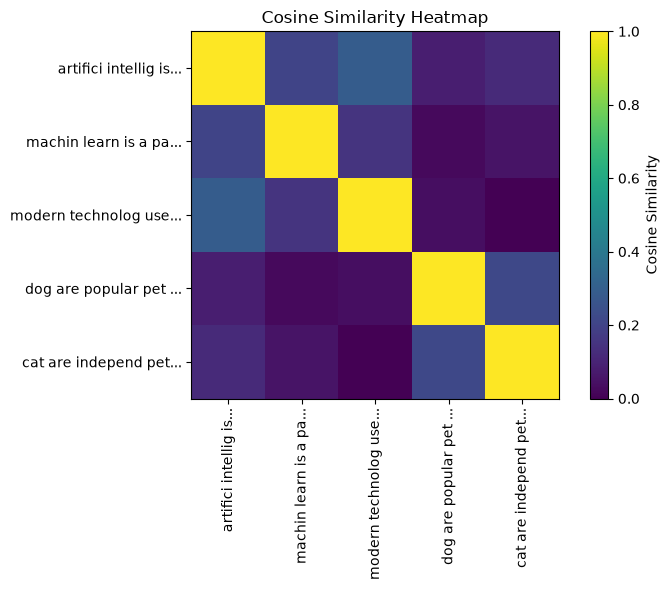

In [7]:
def get_texts():
    """
    Get the texts you want to analyse. Either API fetching, Kaggle or any other source.

    Args:
        None: None.

    Returns:
        list: list of texts.
    """
    return [
    "Artificial intelligence is changing the way people use computers and technology.",
    "Machine learning is a part of artificial intelligence that allows computers to learn from data.",
    "Modern technology uses artificial intelligence to solve complex problems.",
    "Dogs are popular pets because they are friendly, loyal and intelligent animals.",
    "Cats are independent pets that enjoy sleeping, playing and spending time with people."
]

texts = get_texts()
texts_processed = process_texts(texts)
cosine_matrix = calcuate_tfidf(texts_processed)
visualize_data(cosine_matrix, texts_processed)